# Null models: what they keep, and the sequences they make

A null model makes sequences that match a natural sequence in whatever we choose to keep, and are random in everything else. If we want to know whether some feature of a sequence means anything (its charge patterning, say), we compare it with the same feature in the sequence's nulls. If the nulls have it too, it comes from what we kept; if they don't, it comes from something the null model threw away. So the null model we pick decides the question we're asking.

`sparrow.null` has four null models. Every one of them gives each null exactly the length and the composition of the sequence it was made from, and they differ in what else they keep:

| Model | What else each null keeps | Needs a background |
|---|---|---|
| `BlockShuffle(k)` | the sequence cut into blocks of `k` residues, and the blocks shuffled | no |
| `KletShuffle(k)` | exactly the sequence's count of every run of `k` residues (every dipeptide, with `k=2`) | no |
| `KmerBackground(k)` | the local grammar of a background set of natural sequences, by rebuilding the sequence's residues from the background's k-mers | yes |
| `MarkovBackground(order)` | the local grammar of a background, by drawing residues one at a time from the background's Markov chain | yes |

This notebook works through what each model does, looks at the sequences they make, and then measures what they keep and what they don't:

1. Setting up
2. How the shuffles work, on toy sequences
3. A background: the yeast IDRome
4. The nulls of a natural IDR
5. What each model keeps, measured
6. How much each option keeps
7. Using nulls: is RIO1's charge patterning unusual?
8. The other tail: aromatic spacing in hnRNPA1
9. Seeds
10. Which null model to use

The sections build on each other, so run the notebook from the top. The Null Models section of the docs has a page on each model, with the details of how it works.

## 1. Setting up

In [1]:
import re
import time
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import metapredict as meta
import numpy as np
import protfasta
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from sparrow import Protein
from sparrow.null import BlockShuffle, KletShuffle, KmerBackground, MarkovBackground
from sparrow.sparrow_exceptions import NullModelWarning

%matplotlib inline

# Arial throughout, with the text kept as text (so it stays editable in Illustrator) when a figure is saved
plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": 9,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
    }
)

# the xmgrace colours, in order
XMGRACE = ["black", "red", "blue", "green", "purple"]

# how many nulls we make of each sequence when we measure them
NULL_COUNT = 1000

# the seed every null below is made with, so the notebook gives the same nulls every time it runs
SEED = 1

A few helpers, used throughout: one prints sequences one above the other, one draws them as rows of coloured residues, and the rest are the simple sequence statistics we measure the nulls with.

In [2]:
# the residues the sequence figures colour, by class, each with its xmgrace colour; every other residue is left white
RESIDUE_CLASSES = {
    "Hydrophobic (A, I, L, M, V)": ("AILMV", "black"),
    "Acidic (D, E)": ("DE", "red"),
    "Basic (K, R)": ("KR", "blue"),
    "Aromatic (F, W, Y)": ("FWY", "green"),
    "Q and N": ("QN", "purple"),
}

# only the charged residues, for looking at charge patterning
CHARGE_CLASSES = {
    "Acidic (D, E)": ("DE", "red"),
    "Basic (K, R)": ("KR", "blue"),
}


def print_aligned(sequences, width=60):
    """Print sequences one above the other, in lines of the same residues.

    Parameters
    ----------
    sequences : dict
        Each sequence (str), by the label printed beside it.
    width : int, optional
        How many residues go on each line. Default 60.
    """
    label_width = max(len(label) for label in sequences)
    length = max(len(sequence) for sequence in sequences.values())
    for start in range(0, length, width):
        end = min(start + width, length)
        print(f"{'residues':{label_width}s}  {start + 1}-{end}")
        for label, sequence in sequences.items():
            print(f"{label:{label_width}s}  {sequence[start:end]}")
        print()


def draw_sequences(rows, classes=RESIDUE_CLASSES, width_in=7.0, row_height_in=0.12):
    """Draw sequences as rows of residues, each coloured by its class.

    Parameters
    ----------
    rows : list
        The rows, top to bottom, as (label, sequence) pairs; a sequence of None
        leaves a blank row, to separate groups of rows. Every sequence must have
        the same length.
    classes : dict, optional
        The classes to colour, as {name: (residues, colour)}. Residues in no
        class are white. Default RESIDUE_CLASSES.
    width_in : float, optional
        The width of the figure, in inches. Default 7.
    row_height_in : float, optional
        The height of each row, in inches. Default 0.12.

    Returns
    -------
    matplotlib.figure.Figure, matplotlib.axes.Axes
    """
    lengths = {len(sequence) for _, sequence in rows if sequence is not None}
    assert len(lengths) == 1, "every sequence drawn together must have the same length"
    length = lengths.pop()

    # each residue's class number: 0 for no class, 1 for the first class, and so on
    class_of_residue = {}
    for number, (residues, _) in enumerate(classes.values(), start=1):
        for residue in residues:
            class_of_residue[residue] = number

    grid = np.zeros((len(rows), length))
    for row, (_, sequence) in enumerate(rows):
        if sequence is not None:
            grid[row] = [class_of_residue.get(residue, 0) for residue in sequence]

    colormap = ListedColormap(["white"] + [colour for _, colour in classes.values()])
    figure, ax = plt.subplots(figsize=(width_in, row_height_in * len(rows) + 0.9))
    ax.imshow(
        grid,
        cmap=colormap,
        vmin=-0.5,
        vmax=len(classes) + 0.5,
        aspect="auto",
        interpolation="nearest",
        extent=(0.5, length + 0.5, len(rows) - 0.5, -0.5),
    )
    ax.set_yticks(range(len(rows)), [label for label, _ in rows])
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("Residue")
    handles = [Patch(facecolor=colour, label=name) for name, (_, colour) in classes.items()]
    ax.legend(
        handles=handles, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=len(classes), frameon=False, handlelength=1
    )
    return figure, ax


def dipeptide_counts(sequence):
    """Count every pair of neighbouring residues in a sequence.

    Parameters
    ----------
    sequence : str

    Returns
    -------
    collections.Counter
        The count of each dipeptide, such as 'QQ'.
    """
    return Counter(sequence[i : i + 2] for i in range(len(sequence) - 1))


def dipeptides_shared(sequence, null):
    """The fraction of a sequence's dipeptides that a null has too.

    Each dipeptide is counted as many times as both have it, so a null with
    exactly the sequence's dipeptides scores 1.

    Parameters
    ----------
    sequence : str
    null : str
        A sequence of the same length.

    Returns
    -------
    float
        Between 0 and 1.
    """
    sequence_counts = dipeptide_counts(sequence)
    null_counts = dipeptide_counts(null)
    shared = sum(min(count, null_counts[pair]) for pair, count in sequence_counts.items())
    return shared / (len(sequence) - 1)


def same_neighbours(sequence):
    """The fraction of pairs of neighbouring residues that are the same residue twice, such as 'QQ'.

    Parameters
    ----------
    sequence : str

    Returns
    -------
    float
        Between 0 and 1.
    """
    pairs = len(sequence) - 1
    return sum(sequence[i] == sequence[i + 1] for i in range(pairs)) / pairs


def longest_run(sequence):
    """The length of the longest run of one residue, such as 'QQQQ', in residues.

    Parameters
    ----------
    sequence : str

    Returns
    -------
    int
    """
    return max(len(run.group()) for run in re.finditer(r"(.)\1*", sequence))


def residues_in_runs(sequence, residues, shortest=3):
    """How many of some residues are in runs of one residue at least so long, such as 'QQQ'.

    Parameters
    ----------
    sequence : str
    residues : str
        The residues whose runs are counted, such as 'QN'.
    shortest : int, optional
        The shortest run counted, in residues. Default 3.

    Returns
    -------
    int
        The number of residues in those runs.
    """
    runs = [run.group() for run in re.finditer(r"(.)\1*", sequence)]
    return sum(len(run) for run in runs if run[0] in residues and len(run) >= shortest)


def compare_with_nulls(observed, null_values):
    """How a sequence's value of some feature compares with its nulls' values.

    Parameters
    ----------
    observed : float
        The sequence's value.
    null_values : numpy.ndarray
        The value for each null.

    Returns
    -------
    dict
        'mean' and 'sd' of the nulls; 'percentile', the fraction of nulls below
        the sequence; 'z', the sequence's z-score against the nulls; and 'p',
        the one-sided empirical p-value for a value at least as high as the
        sequence's, (1 + nulls at least that high) / (1 + nulls).
    """
    return {
        "mean": null_values.mean(),
        "sd": null_values.std(),
        "percentile": np.mean(null_values < observed),
        "z": (observed - null_values.mean()) / null_values.std(),
        "p": (1 + np.sum(null_values >= observed)) / (1 + len(null_values)),
    }

## 2. How the shuffles work, on toy sequences

The two shuffles need nothing but the sequence, so they're the easiest to see working.

### The block shuffle

`BlockShuffle(k)` cuts the sequence into blocks of `k` residues and puts the blocks back together in a random order. To see the blocks, we give it a sequence in which every residue is different: the 20 amino acids in the alphabetical order of their one-letter codes. Any run of letters in that order is then a piece of the original, and the second column splits each null wherever a residue doesn't follow the one before it in the alphabet.

The cuts start at a random point, so the first and last blocks can be shorter than `k`. `k` can also be a list, such as `[2, 3]`, to cut the sequence into blocks of several sizes, with each size covering an equal share of the residues.

In [3]:
alphabet = "ACDEFGHIKLMNPQRSTVWY"


def split_where_out_of_order(null):
    """Split a null of the alphabet wherever a residue does not follow the one before it.

    Parameters
    ----------
    null : str
        A null of ``alphabet``.

    Returns
    -------
    str
        The pieces of the original, separated by spaces.
    """
    pieces = [null[0]]
    for previous, residue in zip(null, null[1:]):
        if alphabet.index(residue) == alphabet.index(previous) + 1:
            pieces[-1] += residue
        else:
            pieces.append(residue)
    return " ".join(pieces)


print(f"{'':12s}{alphabet}")
for k in [1, 2, 4, [2, 3]]:
    null = BlockShuffle(k=k).generate(alphabet, seed=SEED)[0]
    print(f"k={str(k):10s}{null}    {split_where_out_of_order(null)}")

            ACDEFGHIKLMNPQRSTVWY
k=1         SMHFQLPYVKGANDREICWT    S M H F Q L P Y V K G A N D R E I C W T
k=2         PQACFGWYHITVRSKLDEMN    PQ AC FG WY HI TV RS KL DE MN
k=4         VWYQRSTLMNPACDEFGHIK    VWY QRST LMNP ACDEFGHIK
k=[2, 3]    GHACIKRSTVWLMNYPQDEF    GH AC IK RSTVW LMN Y PQ DEF


With `k=1` this is a plain shuffle. With larger `k` the pieces get longer, so more of each residue's neighbours are kept. Two blocks that happen to land next to each other in their original order read as one piece, so a piece can be longer than `k`.

### The k-let shuffle

`KletShuffle(k)` keeps something different: exactly the sequence's count of every run of `k` residues. With `k=2`, every null has exactly the sequence's dipeptides, as many times as the sequence has them, in a new order. It's the protein version of the dinucleotide shuffle of Altschul & Erickson (1985), and the first and last `k - 1` residues stay where they are.

That makes it far stricter than a block shuffle. Every dipeptide in the alphabet is different, and there is only one way to chain them all together, so the alphabet's only k-let shuffle is itself:

In [4]:
KletShuffle(k=2).generate(alphabet, count=3, seed=SEED)

['ACDEFGHIKLMNPQRSTVWY', 'ACDEFGHIKLMNPQRSTVWY', 'ACDEFGHIKLMNPQRSTVWY']

A sequence with repeated residues has room to move. Here we make three nulls of a short sequence with each shuffle, and check what each kept: whether the null has the sequence's composition and its dipeptides, and what fraction of the sequence's dipeptides it shares.

In [5]:
toy = "MEEEKKKKSSSTTTDDDQQQQEKEKRRRDDDESSGGKKKEEE"

toy_models = {
    "BlockShuffle(k=1)": BlockShuffle(k=1),
    "BlockShuffle(k=3)": BlockShuffle(k=3),
    "KletShuffle(k=2)": KletShuffle(k=2),
}

print(f"{'sequence':19s} {toy}")
for label, model in toy_models.items():
    for null in model.generate(toy, count=3, seed=SEED):
        same_composition = Counter(null) == Counter(toy)
        same_dipeptides = dipeptide_counts(null) == dipeptide_counts(toy)
        print(
            f"{label:19s} {null}   composition: {same_composition!s:5s}  dipeptides: {same_dipeptides!s:5s}  "
            f"dipeptides shared: {dipeptides_shared(toy, null):.0%}"
        )

sequence            MEEEKKKKSSSTTTDDDQQQQEKEKRRRDDDESSGGKKKEEE
BlockShuffle(k=1)   EKSEREKDKRKTEQDMKSTDEDQSGGKDETESEKKSEQDQRK   composition: True   dipeptides: False  dipeptides shared: 34%
BlockShuffle(k=1)   ERTKSEEDDSQSMKGDDREKKEEEGQSEKQKSRDTKDEQTKK   composition: True   dipeptides: False  dipeptides shared: 32%
BlockShuffle(k=1)   TDDKDTSEKDKDSETKEKGQKQKQEKEKRQEDRSEGMESSER   composition: True   dipeptides: False  dipeptides shared: 29%
BlockShuffle(k=3)   EKKDDQEEEKRRQQQSGGMEEKKSSSTRDDDESEKEKKKTTD   composition: True   dipeptides: False  dipeptides shared: 78%
BlockShuffle(k=3)   KSSGGKEEERRRSTTESSMQQETDDKKKEEKKEDDDDQQKEK   composition: True   dipeptides: False  dipeptides shared: 73%
BlockShuffle(k=3)   DQQKKKESSMDDDKEKRRRTDDEEESTTEEKKEKSSQQEGGK   composition: True   dipeptides: False  dipeptides shared: 76%
KletShuffle(k=2)    MEKKKSGGKRRRDEEKKEEEESSSSTTTDDDDDQQQQEKKKE   composition: True   dipeptides: True   dipeptides shared: 100%
KletShuffle(k=2)    MEEEEKEKSSTTTDDDDDEKKKKKKRR

Every null has the sequence's composition. The plain shuffle keeps about a third of the sequence's dipeptides, mostly by chance. The block shuffle with `k=3` keeps at least two thirds, since two of the three pairs of neighbours in each block stay together, and a few more by chance. The k-let shuffle keeps all of them, and starts with M and ends with E, as the sequence does.

## 3. A background: the yeast IDRome

The other two models don't take their grammar from the sequence. They learn it from a *background*, a large set of natural sequences, and give each null the background's local grammar in place of the sequence's own. A null from a background model asks whether a sequence is unusual compared with the sequences the background is made of. So the background is part of the question: here we want to know whether a yeast IDR is unusual for a yeast IDR, so the background is every IDR in the yeast proteome.

The yeast proteome is in sparrow's examples. We find its IDRs with metapredict, which takes a few seconds. metapredict warns that a few proteins are shorter than the window it smooths over to find IDRs, and shrinks the window for them.

In [6]:
# the S. cerevisiae S288c reference proteome (UniProt UP000002311), from sparrow's examples
PROTEOME_FASTA = "../../examples/yeast_proteome_gin/uniprotkb_proteome_UP000002311_2026_07_27.fasta"

proteome = protfasta.read_fasta(PROTEOME_FASTA)


def protein_with_gene(gene):
    """The sequence of the one protein in the proteome with a gene name.

    Parameters
    ----------
    gene : str
        The gene name, as in the GN= field of its UniProt header.

    Returns
    -------
    str
    """
    matches = [sequence for header, sequence in proteome.items() if f" GN={gene} " in header]
    assert len(matches) == 1, f"{len(matches)} proteins have the gene name {gene}"
    return matches[0]


start = time.time()
predictions = meta.predict_disorder(proteome, return_domains=True)
yeast_idrs = [idr for prediction in predictions.values() for idr in prediction.disordered_domains]

print(f"{len(yeast_idrs):,} IDRs in {len(proteome):,} proteins, found in {time.time() - start:.1f} s")
print(f"{sum(len(idr) for idr in yeast_idrs):,} residues in all")

8,199 IDRs in 6,067 proteins, found in 5.6 s
805,885 residues in all


/Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict/backend/predictor.py:102: RuntimeWarning: One or more sequences are no longer than the smoothing window used for domain decomposition (2*minimum_IDR_size residues). For those sequences the window is shrunk to match the sequence length.
  return_tuple = _domain_definition.get_domains(s,


Fitting a background model counts every k-mer in the background, which takes a fraction of a second. Both models fit here count runs of up to three residues: `KmerBackground(k=3)` builds its nulls from 3-mers, and `MarkovBackground(order=2)` draws each residue given the two before it.

In [7]:
start = time.time()
kmer_background = KmerBackground(k=3).fit(yeast_idrs)
markov_background = MarkovBackground(order=2).fit(yeast_idrs)
print(f"fit both models in {time.time() - start:.2f} s")

fit both models in 0.02 s


The background needs to be large enough to count its k-mers well. There are 20<sup>k</sup> possible k-mers, 8,000 3-mers and 160,000 4-mers, and the yeast IDRs have about 100 of each 3-mer but only about 5 of each 4-mer. A model that counts 4-mers fits anyway, with whatever counts there are, but warns:

In [8]:
KmerBackground(k=4).fit(yeast_idrs)

/var/folders/2n/xtzsyspd32v6vglg_pd5gmw80000gn/T/ipykernel_88252/3099267792.py:1: NullModelWarning: The background has 781288 4-mers, an average of 4.9 for each of the 160000 possible ones (at least 10 is recommended), so most of their frequencies rest on a handful of counts. Fit KmerBackground to a larger background, or use shorter k-mers.
  KmerBackground(k=4).fit(yeast_idrs)


KmerBackground(k=4)

## 4. The nulls of a natural IDR

Sup35 is the yeast prion protein, and its NM region (residues 1-254, which metapredict finds as one IDR) is disordered. The N domain, roughly the first 120 residues, is rich in Q, N, Y and G, and the M domain after it is highly charged.

We make nulls of it with five models: two block shuffles, a k-let shuffle, and the two background models we fit above. A model can make nulls of a sequence as a string or as a `Protein`.

In [9]:
sup35_nm = protein_with_gene("SUP35")[:254]

MODELS = {
    "BlockShuffle(k=1)": BlockShuffle(k=1),
    "BlockShuffle(k=3)": BlockShuffle(k=3),
    "KletShuffle(k=2)": KletShuffle(k=2),
    "KmerBackground(k=3)": kmer_background,
    "MarkovBackground(order=2)": markov_background,
}

one_null_each = {label: model.generate(sup35_nm, seed=SEED)[0] for label, model in MODELS.items()}
print_aligned({"Sup35 NM": sup35_nm, **one_null_each})

residues                   1-60
Sup35 NM                   MSDSNQGNNQQNYQQYSQNGNQQQGNNRYQGYQAYNAQAQPAGGYYQNYQGYSGYQQGGY
BlockShuffle(k=1)          NQQQAQQPGQENQYAMAQNKILFLDPGVYNTSVKNPNKQPTEMQTRNEYDQNAGAMQQQF
BlockShuffle(k=3)          NQGTKVPQGPVQNPDATKDKKYSGNFNYNPEPTEEKETKAESYQQYQDMQGGGRGELPKL
KletShuffle(k=2)           MSAGNYSDDAQKIKVELPKQGYQGGYQKQQGRGYNGNDFNYQQNQTKLQSQYKKEESSEK
KmerBackground(k=3)        YPGNDGEEGKVNETNEILKKKQQKAPKEESGLKYNIQGNQEEPSYNEQQQQQLKTGQFAS
MarkovBackground(order=2)  TQPQNNDEEKQKTEFNNGITAQQQQQQNAGESNKQQQKAQANYYQPPYSNFETVSDNEED

residues                   61-120
Sup35 NM                   QQYNPDAGYQQQYNPQGGYQQYNPQGGYQQQFNPQGGRGNYKNFNYNNNLQGYQAGFQPQ
BlockShuffle(k=1)          ENKKLIKVEKENALTGVNPGKYIENSPQEATGDLQERLAGNPYYTNGAENANEEGAASYE
BlockShuffle(k=3)          VMISEEEPQQGQGGLANTEEQFNGGYAAPQPQMSLEEVKTENYKQQYNTNNANVKKSQNQ
KletShuffle(k=2)           TEEKPQEEQGYNTEPVDAEPQQFQGYNFQGGFNAGGMSDSLKKEVGYQAQADEEKVEEEV
KmerBackground(k=3)        VGYPSSNNSQQMEQEYYYAPGANPYN

Colouring the residues by class makes the differences easier to see. Here are three nulls from each model below the sequence.

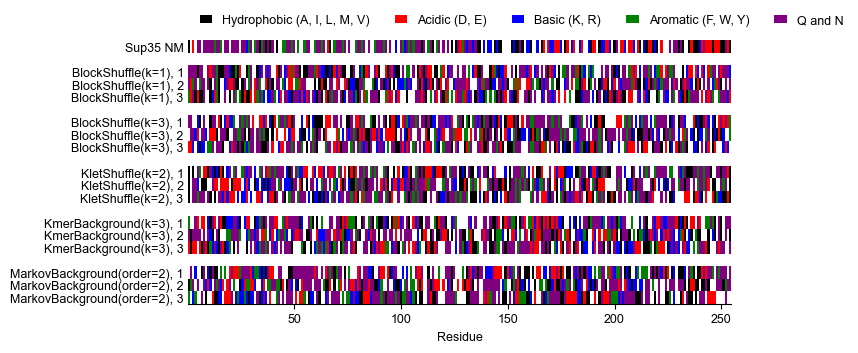

In [10]:
rows = [("Sup35 NM", sup35_nm)]
for label, model in MODELS.items():
    rows.append(("", None))
    for number, null in enumerate(model.generate(sup35_nm, count=3, seed=SEED), start=1):
        rows.append((f"{label}, {number}", null))

figure, ax = draw_sequences(rows)

Two things stand out. First, in Sup35 NM the Q, N and aromatic residues are in the first half and the charged ones in the second, but in every null they're spread along the whole length. None of these models keeps where residues are, so the order of the domains is one of the things all of them strip out. Second, the Markov chain's nulls have long runs of Q (the longer purple stretches), longer than any Sup35 NM has, since runs of Q are common in yeast IDRs. Section 5 measures both.

## 5. What each model keeps, measured

We make 1,000 nulls of Sup35 NM with each model, and first check the one thing every model promises: that every null has exactly the sequence's composition.

In [11]:
start = time.time()
sup35_nulls = {label: model.generate(sup35_nm, count=NULL_COUNT, seed=SEED) for label, model in MODELS.items()}
print(f"made {len(MODELS) * NULL_COUNT:,} nulls in {time.time() - start:.1f} s")

for label, nulls in sup35_nulls.items():
    assert all(Counter(null) == Counter(sup35_nm) for null in nulls), label
print("every null has Sup35 NM's composition exactly")

made 5,000 nulls in 2.8 s
every null has Sup35 NM's composition exactly


Then four things about the order of the residues:

* **Dipeptides shared with the sequence**, the fraction of Sup35 NM's dipeptides each null has too;
* **Neighbours that are the same residue**, the fraction of pairs of neighbouring residues that are one residue twice, such as QQ or GG, which is high in sequences with runs and repeats;
* **Q and N in runs**, how many of the Q and N residues are in a run of at least three of one residue, such as QQQ;
* **The longest run of one residue**, such as QQQQ.

For each, the figure shows the mean over the nulls (the point) and the range the middle 90% of them fall in (the line), with Sup35 NM's own value as the red line.

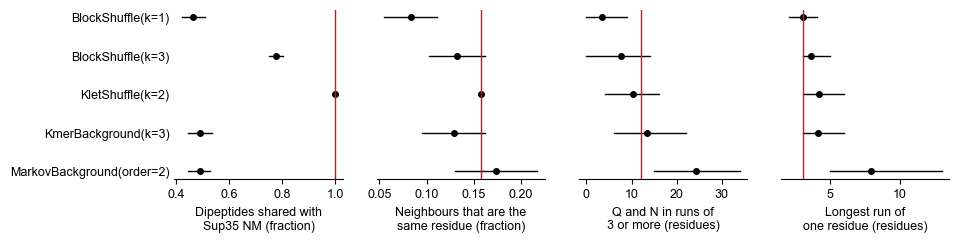

                              shared     same  Q/N runs  longest
Sup35 NM                       1.000    0.158        12        3
BlockShuffle(k=1)              0.466    0.083       3.4      3.1
BlockShuffle(k=3)              0.778    0.133       7.7      3.6
KletShuffle(k=2)               1.000    0.158      10.4      4.2
KmerBackground(k=3)            0.490    0.129      13.5      4.1
MarkovBackground(order=2)      0.488    0.173      24.2      7.9


In [12]:
measures = {
    "Dipeptides shared with\nSup35 NM (fraction)": (
        1.0,
        {
            label: np.array([dipeptides_shared(sup35_nm, null) for null in nulls])
            for label, nulls in sup35_nulls.items()
        },
    ),
    "Neighbours that are the\nsame residue (fraction)": (
        same_neighbours(sup35_nm),
        {label: np.array([same_neighbours(null) for null in nulls]) for label, nulls in sup35_nulls.items()},
    ),
    "Q and N in runs of\n3 or more (residues)": (
        residues_in_runs(sup35_nm, "QN"),
        {label: np.array([residues_in_runs(null, "QN") for null in nulls]) for label, nulls in sup35_nulls.items()},
    ),
    "Longest run of\none residue (residues)": (
        longest_run(sup35_nm),
        {label: np.array([longest_run(null) for null in nulls]) for label, nulls in sup35_nulls.items()},
    ),
}

figure, axes = plt.subplots(1, len(measures), figsize=(10, 2.2), sharey=True)
positions = np.arange(len(MODELS))[::-1]
for ax, (measure, (observed, values_by_model)) in zip(axes, measures.items()):
    for position, values in zip(positions, values_by_model.values()):
        low, high = np.percentile(values, [5, 95])
        ax.plot([low, high], [position, position], color="black", linewidth=1)
        ax.plot(values.mean(), position, "o", color="black", markersize=4)
    ax.axvline(observed, color="red", linewidth=1)
    ax.set_xlabel(measure)
axes[0].set_yticks(positions, list(MODELS))
axes[0].tick_params(axis="y", length=0)
axes[0].spines["left"].set_visible(False)
for ax in axes[1:]:
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
plt.show()

print(f"{'':27s}{'shared':>9s}{'same':>9s}{'Q/N runs':>10s}{'longest':>9s}")
sequence_values = [sequence_value for sequence_value, _ in measures.values()]
print(
    f"{'Sup35 NM':27s}{sequence_values[0]:9.3f}{sequence_values[1]:9.3f}{sequence_values[2]:10d}{sequence_values[3]:9d}"
)
for label in MODELS:
    means = [null_values[label].mean() for _, null_values in measures.values()]
    print(f"{label:27s}{means[0]:9.3f}{means[1]:9.3f}{means[2]:10.1f}{means[3]:9.1f}")

Each model keeps what it says it does, and nothing more:

* **The plain shuffle** keeps about half of the dipeptides, which is what Sup35 NM's composition gives by chance. Half as many of its neighbours are the same residue as in the sequence, and it has few runs, since the sequence's runs and repeats are broken up.
* **The block shuffle with `k=3`** keeps at least two thirds of the dipeptides, the pairs inside each block, and so more of the sequence's same-residue neighbours and runs.
* **The k-let shuffle** keeps every dipeptide, so its same-residue neighbours match Sup35 NM's exactly. Its longest runs are a little longer than the sequence's, since a sequence with several QQ (or EE) pairs can have them chained together into a longer run than any it has.
* **The background models** keep no more of Sup35 NM's dipeptides than the plain shuffle does. What they keep is the yeast IDRs' grammar, which shows in the runs. The k-mer model has about as many Q and N in runs as Sup35 NM, and the Markov chain twice as many, with a longest run of about 8, nearly always of Q. A run of 8 Qs in a Markov null is the yeast IDRs' grammar, drawn in Sup35 NM's composition.

The Markov chain makes longer runs than the k-mer model, from the same 3-mers, because it draws each residue given the two before it. Once it's in a run of Q, the chance that the next residue is Q too is the chance a yeast IDR has a Q after QQ, which is high, so the run tends to go on. The k-mer model draws its blocks of three with no regard to the blocks beside them, and puts them in a random order, so a run carries on from one block into the next only by chance.

### Where residues are

None of the models keeps where along the sequence a residue is. Here is the fraction of Q, N, Y and G in a window of 15 residues along Sup35 NM (black), along one null from each model (blue), and averaged over all 1,000 nulls (red). The nulls' average is flat: on average every position of a null has the composition of the whole sequence.

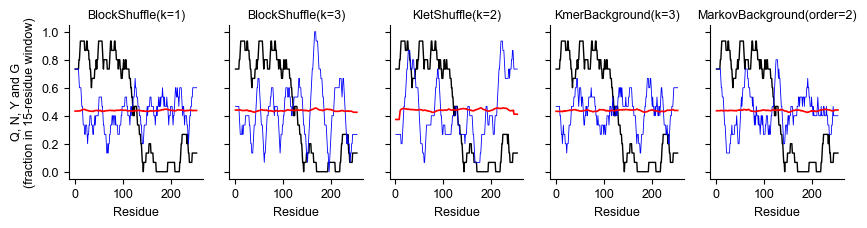

In [13]:
# the residues that make up most of the N domain, and the window their local fraction is measured over
N_DOMAIN_RESIDUES = list("QNYG")
WINDOW_SIZE = 15


def n_domain_profile(sequence):
    """The fraction of Q, N, Y and G in a window centred on each residue.

    Parameters
    ----------
    sequence : str

    Returns
    -------
    numpy.ndarray
        One value for each residue.
    """
    return Protein(sequence).linear_composition_profile(N_DOMAIN_RESIDUES, window_size=WINDOW_SIZE)


residue_numbers = np.arange(1, len(sup35_nm) + 1)
sequence_profile = n_domain_profile(sup35_nm)

figure, axes = plt.subplots(1, len(MODELS), figsize=(10, 2), sharey=True)
for ax, (label, nulls) in zip(axes, sup35_nulls.items()):
    mean_profile = np.mean([n_domain_profile(null) for null in nulls], axis=0)
    ax.plot(residue_numbers, sequence_profile, color="black", linewidth=1)
    ax.plot(residue_numbers, n_domain_profile(nulls[0]), color="blue", linewidth=0.6)
    ax.plot(residue_numbers, mean_profile, color="red", linewidth=1.2)
    ax.text(0.5, 1.02, label, transform=ax.transAxes, ha="center", va="bottom")
    ax.set_xlabel("Residue")
axes[0].set_ylabel(f"Q, N, Y and G\n(fraction in {WINDOW_SIZE}-residue window)")
plt.show()

The k-let shuffle's average dips at both ends, since its first and last residues are always Sup35 NM's, both M, which is none of Q, N, Y or G. Apart from that, everything the sequence's domain structure says is gone from every model's nulls. That's the point of a null, but it's worth knowing: a feature that comes from where residues are, such as a charged region next to a Q/N-rich one, is never kept.

## 6. How much each option keeps

Each model has one option that sets how much of the local order it keeps: `k` for the shuffles and `KmerBackground`, and `order` for `MarkovBackground`. `MarkovBackground(order)` works with runs of `order + 1` residues (each residue given the `order` before it), so we plot it at `order + 1`, beside the models that work with runs of `k`.

Fitting a background model that counts 4-mers warns that the yeast IDRs are too few to count them well, as we saw above, and the Markov chain of order 3 warns that a few of its residues had to be drawn given fewer residues before them than its order, since the background never follows those residues with any of the ones the null had left. Here we record the warnings and print each once.

In [14]:
SWEEP_COUNT = 500

sweep = {
    "BlockShuffle": [(k, BlockShuffle(k=k)) for k in range(1, 9)],
    "KletShuffle": [(k, KletShuffle(k=k)) for k in range(1, 5)],
    "KmerBackground": [(k, KmerBackground(k=k)) for k in range(1, 5)],
    "MarkovBackground": [(order + 1, MarkovBackground(order=order)) for order in range(0, 4)],
}

sweep_results = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", NullModelWarning)
    for family, models in sweep.items():
        sweep_results[family] = []
        for run_length, model in models:
            if model.needs_background:
                model.fit(yeast_idrs)
            nulls = model.generate(sup35_nm, count=SWEEP_COUNT, seed=SEED)
            sweep_results[family].append(
                {
                    "model": repr(model),
                    "run_length": run_length,
                    "shared": np.mean([dipeptides_shared(sup35_nm, null) for null in nulls]),
                    "longest": np.mean([longest_run(null) for null in nulls]),
                    "distinct": len(set(nulls)),
                }
            )

for message in sorted({str(warning.message) for warning in caught}):
    print(f"NullModelWarning: {message}\n")

print(f"{'model':28s}{'shared':>8s}{'longest':>9s}{'distinct':>10s}")
for results in sweep_results.values():
    for result in results:
        print(f"{result['model']:28s}{result['shared']:8.3f}{result['longest']:9.1f}{result['distinct']:10d}")




model                         shared  longest  distinct
BlockShuffle(k=1)              0.466      3.0       500
BlockShuffle(k=2)              0.694      3.6       500
BlockShuffle(k=3)              0.778      3.6       500
BlockShuffle(k=4)              0.824      3.6       500
BlockShuffle(k=5)              0.857      3.4       500
BlockShuffle(k=6)              0.877      3.3       500
BlockShuffle(k=7)              0.890      3.3       500
BlockShuffle(k=8)              0.904      3.3       500
KletShuffle(k=1)               0.467      3.1       500
KletShuffle(k=2)               1.000      4.1       500
KletShuffle(k=3)               1.000      3.7       500
KletShuffle(k=4)               1.000      3.0       500
KmerBackground(k=1)            0.468      3.1       500
KmerBackground(k=2)            0.485      3.5       500
KmerBackground(k=3)            0.491      4.1       500
KmerBackground(k=4)            0.492      4.9       500
MarkovBackground(order=0)      0.467      3.1

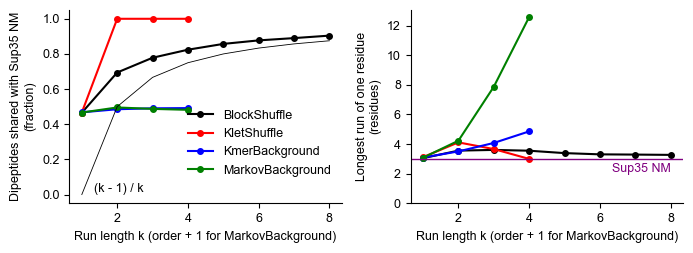

In [15]:
figure, (shared_ax, longest_ax) = plt.subplots(1, 2, figsize=(7, 2.6))

for colour, (family, results) in zip(XMGRACE, sweep_results.items()):
    run_lengths = [result["run_length"] for result in results]
    shared_ax.plot(
        run_lengths, [result["shared"] for result in results], "o-", color=colour, markersize=4, label=family
    )
    longest_ax.plot(
        run_lengths, [result["longest"] for result in results], "o-", color=colour, markersize=4, label=family
    )

# a block shuffle keeps at least the k - 1 pairs inside each block of k
block_sizes = np.arange(1, 9)
shared_ax.plot(block_sizes, (block_sizes - 1) / block_sizes, color="black", linewidth=0.6)
shared_ax.text(1.35, 0, "(k - 1) / k", ha="left", va="bottom")

longest_ax.axhline(longest_run(sup35_nm), color="purple", linewidth=1)
longest_ax.text(8, longest_run(sup35_nm) - 0.3, "Sup35 NM", color="purple", ha="right", va="top")
longest_ax.set_ylim(0, None)

for ax in (shared_ax, longest_ax):
    ax.set_xlabel("Run length k (order + 1 for MarkovBackground)")
shared_ax.set_ylabel("Dipeptides shared with Sup35 NM\n(fraction)")
longest_ax.set_ylabel("Longest run of one residue\n(residues)")
shared_ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.08))
plt.tight_layout()
plt.show()

What each option does follows from how each model works:

* **The block shuffle** keeps more of the sequence's dipeptides as `k` grows, always a little more than the (k - 1)/k inside the blocks.
* **The k-let shuffle** keeps every dipeptide from `k=2` on, and from `k=3` every tripeptide too. Each step up leaves fewer sequences with exactly the sequence's k-lets. Sup35 NM is long enough to still have many (the last column of the table counts the different nulls in 500), but a short sequence soon has only a few, as below.
* **The background models** keep no more of the sequence's dipeptides however long their k-mers are, since their grammar is the background's, not the sequence's. Longer k-mers carry more of the background's grammar, and for yeast IDRs that means longer runs: the Markov chain that draws each residue given the three before it makes runs of a dozen Q. `k=1` and `order=0` keep no grammar at all, and are a plain shuffle.

Here is the 42-residue toy sequence from section 2 again: how many different nulls there are in 1,000 from each k-let shuffle, and how many of them are the sequence itself.

In [16]:
for k in [2, 3, 4]:
    nulls = KletShuffle(k=k).generate(toy, count=NULL_COUNT, seed=SEED)
    print(
        f"KletShuffle(k={k}): {len(set(nulls)):4d} different nulls, {sum(null == toy for null in nulls):4d} of them the sequence"
    )

KletShuffle(k=2): 1000 different nulls,    0 of them the sequence
KletShuffle(k=3):  678 different nulls,    1 of them the sequence


KletShuffle(k=4):    2 different nulls,  493 of them the sequence


With `k=4`, there's only one other sequence with exactly the toy's 4-lets, and about half the nulls are the sequence itself. The model doesn't refuse a sequence like this, since it's a true answer (the k-lets all but fix the sequence), but a null distribution with two members isn't much of a distribution, so `len(set(nulls))` is worth checking for short sequences.

## 7. Using nulls: is RIO1's charge patterning unusual?

Nulls are for asking whether some feature of a sequence is more than what we kept would give by itself. RIO1's C-terminal IDR (residues 385-484) has a block of acidic residues followed by a block of basic ones, so its charges are segregated: its kappa, which goes from 0 for well-mixed charges to 1 for charges in two blocks, is high for an IDR. But is it higher than its nulls'? That depends on which null we ask.

In [17]:
rio1_idr = protein_with_gene("RIO1")[384:484]
observed_kappa = Protein(rio1_idr).kappa
print(rio1_idr)
print(f"kappa = {observed_kappa:.3f}")

NFAASEQFEFDNADHECSSGTEEFSDDEEDGSSGSEEDDEEEGEYYDDDEPKVLKGKKHEDKDLKKLRKQEAKDAKREKRKTKVKKHIKKKLVKKTKSKK
kappa = 0.449


The charged residues of the sequence and of two nulls from each model:

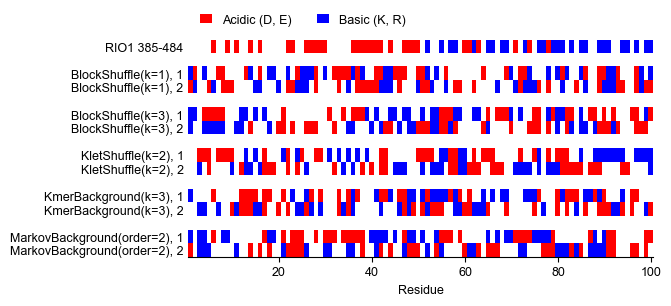

In [18]:
rows = [("RIO1 385-484", rio1_idr)]
for label, model in MODELS.items():
    rows.append(("", None))
    for number, null in enumerate(model.generate(rio1_idr, count=2, seed=SEED), start=1):
        rows.append((f"{label}, {number}", null))

figure, ax = draw_sequences(rows, classes=CHARGE_CLASSES, width_in=6)

Now 1,000 nulls from each model, the kappa of each, and how RIO1's kappa compares: the nulls' mean and standard deviation, the fraction of nulls below RIO1 (its percentile), its z-score, and the one-sided empirical p-value, (1 + the nulls with a kappa at least as high) / (1 + the nulls). With 1,000 nulls, the smallest p-value we can get is 1/1001.

In [19]:
start = time.time()
rio1_kappas = {
    label: np.array([Protein(null).kappa for null in model.generate(rio1_idr, count=NULL_COUNT, seed=SEED)])
    for label, model in MODELS.items()
}
print(f"made and scored {len(MODELS) * NULL_COUNT:,} nulls in {time.time() - start:.1f} s\n")

print(f"{'':27s}{'mean':>7s}{'sd':>7s}{'percentile':>12s}{'z':>7s}{'p':>9s}")
for label, kappas in rio1_kappas.items():
    comparison = compare_with_nulls(observed_kappa, kappas)
    print(
        f"{label:27s}{comparison['mean']:7.3f}{comparison['sd']:7.3f}{comparison['percentile']:12.3f}"
        f"{comparison['z']:7.1f}{comparison['p']:9.4f}"
    )

made and scored 5,000 nulls in 1.7 s

                              mean     sd  percentile      z        p
BlockShuffle(k=1)            0.137  0.045       1.000    6.9   0.0010
BlockShuffle(k=3)            0.240  0.055       1.000    3.8   0.0010
KletShuffle(k=2)             0.332  0.039       0.997    3.0   0.0040
KmerBackground(k=3)          0.180  0.055       1.000    4.9   0.0010
MarkovBackground(order=2)    0.243  0.067       0.997    3.1   0.0040


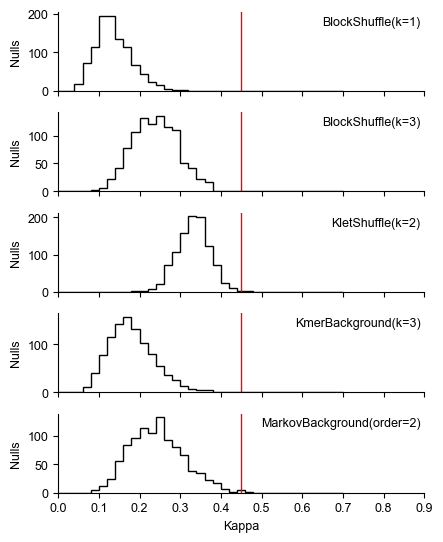

In [20]:
bins = np.linspace(0, 0.7, 36)
figure, axes = plt.subplots(len(MODELS), 1, figsize=(4.5, 5.5), sharex=True)
for ax, (label, kappas) in zip(axes, rio1_kappas.items()):
    ax.hist(kappas, bins=bins, histtype="step", color="black", linewidth=1)
    ax.axvline(observed_kappa, color="red", linewidth=1)
    ax.text(0.99, 0.95, label, transform=ax.transAxes, ha="right", va="top")
    ax.set_ylabel("Nulls")
axes[-1].set_xlim(0, 0.9)
axes[-1].set_xlabel("Kappa")
plt.tight_layout()
plt.show()

RIO1's charges are more segregated than its nulls' against every model, but by how much depends on what the null keeps:

* **Against a plain shuffle**, RIO1 is far out in the tail (z = 6.9), and none of the 1,000 nulls is as blocky. A plain shuffle asks whether the order of RIO1's residues means anything at all, and the answer is clearly yes.
* **Against the k-let shuffle**, it's much closer (z = 3.0), and a few nulls are as blocky. A block of like charges is made of like-charged neighbours (EE, DE, KK, KR), and the k-let shuffle keeps every one of them, so its nulls are fairly blocky too (a mean kappa of 0.33). What's left asks whether RIO1's charges are more segregated than its dipeptides alone would make them, and they are, but by less.
* **Against the background models**, RIO1 is unusual for a yeast IDR, more so against the k-mer model (z = 4.9) than the Markov chain (z = 3.1). The Markov chain's nulls are blockier (a mean kappa of 0.24, against 0.18), since it carries the yeast IDRs' tendency to put like charges together along the whole null, rather than only within blocks of three.

None of these is the right answer by itself. Each asks a different question, so saying which null a z-score is against matters as much as the z-score.

## 8. The other tail: aromatic spacing in hnRNPA1

A feature can be unusual in the other direction too. The low-complexity domain of hnRNPA1 is the textbook case: Martin et al. (2020) showed that its aromatic residues are spread out more evenly than chance would place them, and that this keeps the domain from aggregating as it phase separates. Here we take the C-terminal low-complexity domain of the 372-residue isoform of human hnRNPA1 (residues 186-372), and measure how clustered its aromatic residues are with `compute_kappa_x("FWY")`, the patterning of the aromatic residues against all the others: 0 for evenly mixed, 1 for all in one block.

hnRNPA1 is a human protein and our background is yeast IDRs, so here we use only the shuffles, which need no background and so work for any sequence.

In [21]:
# human hnRNPA1, the 372-residue isoform
hnrnpa1 = "MSKSESPKEPEQLRKLFIGGLSFETTDESLRSHFEQWGTLTDCVVMRDPNTKRSRGFGFVTYATVEEVDAAMNARPHKVDGRVVEPKRAVSREDSQRPGAHLTVKKIFVGGIKEDTEEHHLRDYFEQYGKIEVIEIMTDRGSGKKRGFAFVTFDDHDSVDKIVIQKYHTVNGHNCEVRKALSKQEMASASSSQRGRSGSGNFGGGRGGGFGGNDNFGRGGNFSGRGGFGGSRGGGGYGGSGDGYNGFGNDGGYGGGGPGYSGGSRGYGSGGQGYGNQGSGYGGSGSYDSYNNGGGGGFGGGSGSNFGGGGSYNDFGNYNNQSSNFGPMKGGNFGGRSSGPYGGGGQYFAKPRNQGGYGGSSSSSSYGSGRRF"
hnrnpa1_lcd = hnrnpa1[185:372]

AROMATICS = "FWY"
observed_aromatic_patterning = Protein(hnrnpa1_lcd).compute_kappa_x(AROMATICS)
print(f"{len(hnrnpa1_lcd)} residues, {sum(hnrnpa1_lcd.count(residue) for residue in AROMATICS)} aromatic")
print(f"aromatic patterning = {observed_aromatic_patterning:.3f}\n")

SHUFFLES = {label: model for label, model in MODELS.items() if not model.needs_background}

aromatic_patterning = {
    label: np.array(
        [Protein(null).compute_kappa_x(AROMATICS) for null in model.generate(hnrnpa1_lcd, count=NULL_COUNT, seed=SEED)]
    )
    for label, model in SHUFFLES.items()
}

print(f"{'':19s}{'mean':>7s}{'sd':>7s}{'percentile':>12s}{'z':>7s}")
for label, values in aromatic_patterning.items():
    comparison = compare_with_nulls(observed_aromatic_patterning, values)
    print(
        f"{label:19s}{comparison['mean']:7.3f}{comparison['sd']:7.3f}{comparison['percentile']:12.3f}{comparison['z']:7.1f}"
    )

187 residues, 28 aromatic
aromatic patterning = 0.262



                      mean     sd  percentile      z
BlockShuffle(k=1)    0.501  0.053       0.000   -4.5
BlockShuffle(k=3)    0.445  0.046       0.000   -4.0
KletShuffle(k=2)     0.467  0.044       0.000   -4.6


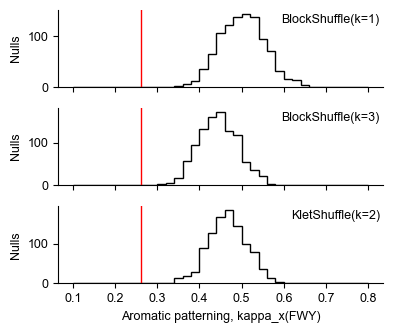

In [22]:
bins = np.linspace(0.1, 0.8, 36)
figure, axes = plt.subplots(len(SHUFFLES), 1, figsize=(4, 3.4), sharex=True)
for ax, (label, values) in zip(axes, aromatic_patterning.items()):
    ax.hist(values, bins=bins, histtype="step", color="black", linewidth=1)
    ax.axvline(observed_aromatic_patterning, color="red", linewidth=1)
    ax.text(0.99, 0.95, label, transform=ax.transAxes, ha="right", va="top")
    ax.set_ylabel("Nulls")
axes[-1].set_xlabel("Aromatic patterning, kappa_x(FWY)")
plt.tight_layout()
plt.show()

Not one of the 1,000 nulls from any of the shuffles has aromatics as evenly spread as hnRNPA1's, so here the answer doesn't depend on the null: the even spacing is more than the composition, the blocks of three, or the dipeptides would give. The percentile, the fraction of nulls below the sequence, is the number to look at for this tail; the p-value in `compare_with_nulls` is for the high tail, as in section 7.

## 9. Seeds

Every model takes a `seed`. With the same seed, a model makes the same nulls of a sequence every time; with `seed=None`, the default, they're different every time.

In [23]:
model = BlockShuffle(k=1)
print(model.generate(toy, count=2, seed=7))
print(model.generate(toy, count=2, seed=7))
print(model.generate(toy, count=2))

['MQTEKKDSEQKEEKKEGEKQERDDKQEDTGDTKSSSKSRRDE', 'SSQRKQQGEGSDSKDDKDRSTKEEKQTEEDEKEMKKTREEDK']
['MQTEKKDSEQKEEKKEGEKQERDDKQEDTGDTKSSSKSRRDE', 'SSQRKQQGEGSDSKDDKDRSTKEEKQTEEDEKEMKKTREEDK']
['EKKSDRKEQETKEDDESMKKTEKRTESEDDGQQDEQKSSKRG', 'DQSQREGKSSKDKEDTERTESRSMEDKKDQEEDKGKKKQTEE']


The nulls depend on the seed and the sequence together. So a loop over many sequences with one seed doesn't give them all the same shuffle, and a sequence gets the same nulls however many other sequences are made alongside it, and in whatever order.

## 10. Which null model to use

What a null keeps is what a comparison with it can't see. A short guide to the question each one asks:

| Model | Keeps, beyond the composition | Asks whether a feature is more than... |
|---|---|---|
| `BlockShuffle(k=1)` | nothing | ...the composition gives. The weakest test: almost any patterning passes. |
| `BlockShuffle(k)` | the neighbours inside blocks of `k` | ...the composition and the short-range order give, roughly; the joins between blocks are new. |
| `KletShuffle(k=2)` | exactly every dipeptide | ...the sequence's own neighbours give. A strict test of longer-range order. |
| `KmerBackground(k)` | the background's k-mers, in the sequence's composition | ...a typical sequence of the background, with this composition, would have. |
| `MarkovBackground(order)` | the background's Markov chain, in the sequence's composition | ...a typical sequence of the background would have, with smooth joins, and with runs as long as the background makes them. |

A few rules of thumb:

* Say which null you used, with its option, whenever you give a z-score or a percentile.
* If a feature is unusual against a strict null (a k-let shuffle) and against a background, it's more than either the sequence's own local order or the background's grammar would give. If it's unusual only against a plain shuffle, it may be nothing more than the sequence's local order.
* A feature that comes only from the composition (FCR, NCPR, hydropathy) is the same in every null, so there is nothing to compare.
* For a background model, choose the background to match the question: IDRs from the same organism, here.

The Null Models section of the docs covers each model in detail, how the background models match the composition exactly, and how to write a new null model.

### References

Altschul SF, Erickson BW (1985) Significance of nucleotide sequence alignments: a method for random sequence permutation that preserves dinucleotide and codon usage. *Mol Biol Evol* 2:526-538.

Martin EW, Holehouse AS, Peran I, Farag M, Incicco JJ, Bremer A, Grace CR, Soranno A, Pappu RV, Mittag T (2020) Valence and patterning of aromatic residues determine the phase behavior of prion-like domains. *Science* 367:694-699.